# Spot-only backtest: long into the deadline, margin short after the ban lifts

**The problem.** `backtest_noahead.ipynb` flips to short at the close of D. D is the first day of the margin-short ban
(停止融券賣出, `suspension.csv` date → end_date, usually 4 trading days D…E). A new margin short (融券) cannot be
placed then; the short leg was only tradable through single-stock futures, which ~40% of Q5 names have.

**The fix.** Everything in spot, in an ordinary stock + margin account:

* **Long:** buy the stock at the close of D−k, sell at the close of D+x. Selling a long is never restricted.
* **Short:** margin short at the close of **E+1**, the first day new margin shorts are allowed again, cover at the
  close of E+1+h. E is the ban end date from `suspension.csv` (published with the ban, before D).
* **Hedge:** each leg is beta-hedged with TAIEX futures (index futures are not affected by the ban).

**What is re-optimised, on in-sample data only:** k ∈ 3…15, x ∈ −3…+3, h ∈ 1…20. The out-of-sample period is
used once, for the chosen parameters.

**Kept from `backtest_noahead.ipynb`:** Q5 = days-to-cover on D−17 ≥ expanding 80th percentile over past events,
20-day turnover ≥ NT$20m, event set D (MOPS ex-div postings + AGM postings, each public before the entry close of
D−k; recomputed for every k), Dimson beta on the 250 days ending D−17, fixed notional per trade.

**Costs (spot, as in `insample.ipynb`):** long round trip **55bp** (30bp sell tax + commission + slippage), margin
short round trip **65bp** (the same plus borrow fee), hedge **β×2bp** per futures trade (β×4bp per leg). These are
higher than the 20bp per leg used for single-stock futures in `backtest_noahead.ipynb`.

## 1. Data
**What this does.** Same TWSE panel, MOPS postings, Q5 cutoff and beta as `backtest_noahead.ipynb`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
K_GRID, X_GRID, H_GRID = np.arange(3, 16), np.arange(-3, 4), np.arange(1, 21)
K_MAX, X_MAX, H_MAX = K_GRID.max(), X_GRID.max(), H_GRID.max()
Q5_PCT, Q5_MIN_HIST = 0.80, 200   # Q5 cutoff: expanding 80th pct of days-to-cover over past events; burn-in of 200 events
SIG_LAG, MIN_VAL20 = 17, 2e7
COST_LONG_BPS, COST_SHORT_BPS, HEDGE_BPS = 55, 65, 2
K_LABEL, H_LABEL = 16, 30    # an event is in-sample only if every leg closes before the cut, out-of-sample only if every entry is after it
MAX_BAN = 10                 # bans longer than this (trading days) are not deadline bans: no short leg
BETA_WIN, BETA_MIN, DIMSON_LAGS = 250, 60, 2
RF = 0.015
EX_TO_D = 4                  # D = ex-date - 4 trading days
CLOSE_AUCTION = "13:25:00"   # an announcement must be posted before this on the entry day

is_stock = lambda s: s.str.fullmatch(r"[1-9]\d{3}")
px = pd.read_csv(DATA / "prices.csv", dtype={"stock_id": str}, parse_dates=["date"])
px = px[is_stock(px.stock_id)].drop_duplicates(["date", "stock_id"]).sort_values(["stock_id", "date"])
exd = pd.read_csv(DATA / "exdiv.csv", dtype={"stock_id": str}, parse_dates=["date"])
exd = exd.dropna(subset=["close_before", "ref_price"]).drop_duplicates(["date", "stock_id"])
exd["adj"] = exd.ref_price / exd.close_before
px = px.merge(exd[["date", "stock_id", "adj"]], on=["date", "stock_id"], how="left")
px["adj"] = px["adj"].fillna(1.0)
px["close_ff"] = px.groupby("stock_id")["close"].ffill()
px["ret"] = px.close / (px.groupby("stock_id")["close_ff"].shift() * px.adj) - 1
px.loc[px.ret.abs() > 0.105, "ret"] = np.nan

idx = pd.read_csv(DATA / "index.csv", parse_dates=["date"]).drop_duplicates("date").sort_values("date").set_index("date")
cal = idx.index
mg = pd.read_csv(DATA / "margin.csv", dtype={"stock_id": str}, parse_dates=["date"])
mg = mg[is_stock(mg.stock_id)].drop_duplicates(["date", "stock_id"])
stocks = pd.Index(sorted(set(px.stock_id) & set(mg.stock_id)))
wide = lambda df, c: df.pivot(index="date", columns="stock_id", values=c).reindex(index=cal, columns=stocks)
R = wide(px, "ret")
SB = wide(mg, "short_bal")
ADV = (wide(px, "volume") / 1000).rolling(20, min_periods=10).mean()
VAL20 = wide(px, "value").rolling(20, min_periods=10).mean()
col = {s: i for i, s in enumerate(stocks)}
T = len(cal); Rv = R.values
CUT = int(T * 2 / 3)
taiex = idx.taiex_tr.pct_change(fill_method=None).fillna(0).values
HEDGE_R = taiex - RF / 252
print(f"{T} trading days {cal[0].date()} -> {cal[-1].date()}; out-of-sample from {cal[CUT].date()}")

2122 trading days 2018-01-02 -> 2026-09-23; out-of-sample from 2023-10-26


## 2. Events, ban end dates, and who knew what when
**What this does.** Builds the same events as `backtest_noahead.ipynb`: ex-div / ex-rights from MOPS postings
(D = ex-date − 4 trading days) and AGM deadlines from `suspension.csv` with their MOPS postings. Each event gets
its ban end date E from `suspension.csv` (same stock, D within one trading day). An ex-div event with no recorded
ban gets E = D + 3, the usual 4-day ban. For each entry day D−k it records whether the posting was public before
that close.

In [2]:
mops = pd.read_csv(DATA / "mops_exdiv.csv", dtype={"stock_id": str, "announce_time": str},
                   parse_dates=["ex_rights_date", "ex_div_date", "announce_date"])
m = mops[mops.stock_id.isin(stocks)].copy()
m["ex"] = m[["ex_rights_date", "ex_div_date"]].min(axis=1)
m = m.dropna(subset=["ex", "announce_date"])
ex_i = cal.searchsorted(m.ex.values)
m = m[(ex_i < T) & (ex_i >= EX_TO_D)]
m["D"] = cal.searchsorted(m.ex.values) - EX_TO_D
m["announce_time"] = m.announce_time.fillna("23:59:59").str.strip()
m = m.sort_values(["stock_id", "D", "announce_date", "announce_time"])
m["grp"] = (m.groupby("stock_id").D.diff().fillna(99) >= 10).cumsum()
ev = m.groupby("grp").agg(stock_id=("stock_id", "first"), D=("D", "first"),
                          announce_date=("announce_date", "first"), announce_time=("announce_time", "first")).reset_index(drop=True)
ev = ev.sort_values(["stock_id", "D"])
ev = ev[ev.groupby("stock_id").D.diff().fillna(99) >= 10].reset_index(drop=True)

sus = pd.read_csv(DATA / "suspension.csv", dtype={"stock_id": str}, parse_dates=["date", "end_date"]).drop_duplicates()
sus["D"] = cal.searchsorted(sus.date.values)
sus["E"] = cal.searchsorted(sus.end_date.values, side="right") - 1      # last ban day; margin shorting reopens on E+1

# Q5 cutoff pool, as in backtest_noahead.ipynb
pool = sus[sus.stock_id.isin(stocks) & (sus.D >= SIG_LAG) & (sus.D < T)].sort_values(["stock_id", "D"])
pool = pool[pool.groupby("stock_id").D.diff().fillna(99) >= 10]
pj, ps = pool.stock_id.map(col).values, pool.D.values - SIG_LAG
pool = pd.DataFrame({"D": pool.D.values, "dtc": SB.values[ps, pj] / ADV.values[ps, pj], "sb": SB.values[ps, pj]})
pool = pool[(pool.sb > 0) & np.isfinite(pool.dtc)].sort_values("D")
POOL_D, POOL_X = pool.D.values, pool.dtc.values
def q5_cutoff(s):
    n = np.searchsorted(POOL_D, s, side="left")
    return np.quantile(POOL_X[:n], Q5_PCT) if n >= Q5_MIN_HIST else np.nan
THR_BY_S = {s: q5_cutoff(s) for s in range(T)}

ban = sus[["stock_id", "D", "E"]].sort_values("E", ascending=False).drop_duplicates(["stock_id", "D"])
ban_end = {(s, d): e for s, d, e in zip(ban.stock_id, ban.D, ban.E)}

def ban_E(sid, D):
    for sh in (0, -1, 1):
        if (sid, D + sh) in ban_end:
            return ban_end[(sid, D + sh)], True
    return D + 3, False

def signal(df):
    df = df[(df.D >= SIG_LAG + 1)].copy()
    df["j"] = df.stock_id.map(col)
    s_ = df.D.values - SIG_LAG
    df["sb"] = SB.values[s_, df.j.values]
    df["dtc"] = df.sb / ADV.values[s_, df.j.values]
    df["val20"] = VAL20.values[s_, df.j.values]
    df["thr"] = [THR_BY_S[s] for s in s_]
    eb = [ban_E(s, d) for s, d in zip(df.stock_id, df.D)]
    df["E"], df["ban_found"] = [e for e, _ in eb], [f for _, f in eb]
    df["ban_len"] = df.E - df.D + 1
    df["can_short"] = (df.ban_len >= 1) & (df.ban_len <= MAX_BAN)
    df = df[df.E + 1 + H_MAX + 1 < T]
    df["Ddate"] = cal[df.D.values]
    df["period"] = np.select([df.D + H_LABEL < CUT, df.D - K_LABEL >= CUT], ["in-sample", "out-of-sample"], "boundary")
    return df[(df.sb > 0) & (df.dtc >= df.thr) & (df.val20 >= MIN_VAL20) & (df.period != "boundary")].reset_index(drop=True)

# ex-div / ex-rights events from MOPS: known at the close of D-k if posted before it
B = signal(ev)
ann_i = cal.searchsorted(B.announce_date.values)                       # first trading day on or after the posting date
same_day_ok = (cal[np.minimum(ann_i, T - 1)] == B.announce_date.values) & (B.announce_time.values < CLOSE_AUCTION)
B["first_close"] = np.where(same_day_ok, ann_i, ann_i + (cal[np.minimum(ann_i, T - 1)] == B.announce_date.values))
B["lead"] = B.D - B.first_close                                        # the D-k entry is feasible only if lead >= k
B["src"] = "ex-div"

# AGM events from suspension.csv, with MOPS posting lead from collect_mops_agm.py
sa = sus[sus.stock_id.isin(stocks)].sort_values(["stock_id", "D"])
sa = sa[sa.groupby("stock_id").D.diff().fillna(99) >= 10]
AG = signal(sa[sa.reason == "股東常會"][["stock_id", "D"]])
agm = pd.read_csv(DATA / "mops_agm.csv", dtype={"stock_id": str}, parse_dates=["D"])
agm["D"] = cal.searchsorted(agm.D.values)
AG = AG.merge(agm.drop_duplicates(["stock_id", "D"])[["stock_id", "D", "matched", "lead"]], on=["stock_id", "D"], how="left")
AG = AG[AG.matched.eq(True)].copy()
AG["src"] = "AGM"

COLS = ["stock_id", "D", "E", "j", "Ddate", "period", "lead", "can_short", "ban_found", "src"]
EV = pd.concat([B[COLS], AG[COLS]], ignore_index=True)
print(f"events (Q5, liquid, posting found): {len(EV):,}  ex-div {(EV.src == 'ex-div').sum():,}, AGM {(EV.src == 'AGM').sum():,}")
print("by period:", EV.period.value_counts().to_dict())
print(f"ban end found in suspension.csv: {EV.ban_found.mean():.0%}; short leg allowed (ban 1-{MAX_BAN} days): {EV.can_short.mean():.0%}")
print("ban length (trading days D..E):", (EV.E - EV.D + 1).value_counts().sort_index().head(8).to_dict())
print("events known at the close of D-k:", {int(k): int((EV.lead >= k).sum()) for k in K_GRID})

events (Q5, liquid, posting found): 1,022  ex-div 461, AGM 561
by period: {'in-sample': 791, 'out-of-sample': 231}
ban end found in suspension.csv: 100%; short leg allowed (ban 1-10 days): 100%
ban length (trading days D..E): {4: 1022}
events known at the close of D-k: {3: 981, 4: 981, 5: 979, 6: 952, 7: 742, 8: 593, 9: 524, 10: 470, 11: 422, 12: 391, 13: 360, 14: 323, 15: 286}


## 3. Beta and leg returns
**What this does.** Dimson beta (lags 0–2) on the 250 days ending D−17, Blume-shrunk, β = 1 with fewer than 60 usable
days. For every event it stores the hedged daily return of the stock (r − β × TAIEX, net of the risk-free rate on the
hedge) around D for the long leg, and around E for the short leg.

In [3]:
M_LAGS = np.column_stack([np.r_[np.full(k, np.nan), taiex[:T - k]] for k in range(DIMSON_LAGS + 1)])

def beta(j, end):
    rows = slice(max(0, end - BETA_WIN + 1), end + 1)
    y, X = Rv[rows, j], M_LAGS[rows]
    ok = np.isfinite(y) & np.isfinite(X).all(1) & (np.abs(y) < 0.095)
    if ok.sum() < BETA_MIN:
        return 1.0
    b = np.linalg.lstsq(np.column_stack([np.ones(ok.sum()), X[ok]]), y[ok], rcond=None)[0][1:].sum()
    return 0.67 * b + 0.33

EV["beta"] = [beta(j, d - SIG_LAG) for j, d in zip(EV.j.values, EV.D.values)]
bta = EV.beta.values[:, None]
OFF_L = np.arange(-K_MAX + 1, X_MAX + 1)          # long earns on D-k+1 ... D+x
DAYS_L = EV.D.values[:, None] + OFF_L[None, :]
RL = np.nan_to_num(Rv[DAYS_L, EV.j.values[:, None]]) - bta * HEDGE_R[DAYS_L]
OFF_S = np.arange(2, H_MAX + 2)                    # short opened at the close of E+1 earns on E+2 ... E+1+h
DAYS_S = EV.E.values[:, None] + OFF_S[None, :]
RS = -(np.nan_to_num(Rv[DAYS_S, EV.j.values[:, None]]) - bta * HEDGE_R[DAYS_S])
COST_L = COST_LONG_BPS / 1e4 + EV.beta.values * 2 * HEDGE_BPS / 1e4
COST_S = COST_SHORT_BPS / 1e4 + EV.beta.values * 2 * HEDGE_BPS / 1e4
print(f"beta: median {EV.beta.median():.2f}, 5-95% {EV.beta.quantile(.05):.2f}-{EV.beta.quantile(.95):.2f}")

beta: median 1.08, 5-95% 0.56-1.64


## 4. The P&L engine and the in-sample grid
**What this does.** For each (k, x, h), the trade set is every event whose posting was public by the close of D−k.
Daily P&L is the sum over open trades (fixed notional, 1 unit per trade); each leg's cost is charged on the day it
closes. Sharpe is annualised from the daily series, in-sample days only.

To avoid picking a lucky spike, parameters are chosen on the **smoothed** grid: each cell's Sharpe is averaged with
its neighbours (±1 in k, x and h). The raw best cell is shown too.

chosen (smoothed grid): buy D-5, sell D-1, short E+1 -> E+1+15: in-sample Sharpe 0.69 (smoothed 0.63)
raw best cell:          buy D-6, sell D+0, short E+1 -> E+1+15: in-sample Sharpe 0.83
long leg alone, best (smoothed): buy D-7, sell D+0, Sharpe 0.15
short leg alone at k=5: best h = 15 (Sharpe 0.69); Sharpe by h: {1: -1.78, 2: -1.13, 3: -0.78, 4: -0.82, 5: -0.45, 6: 0.08, 7: 0.28, 8: 0.2, 9: 0.21, 10: 0.27, 11: 0.44, 12: 0.47, 13: 0.56, 14: 0.6, 15: 0.69, 16: 0.61, 17: 0.55, 18: 0.58, 19: 0.56, 20: 0.57}


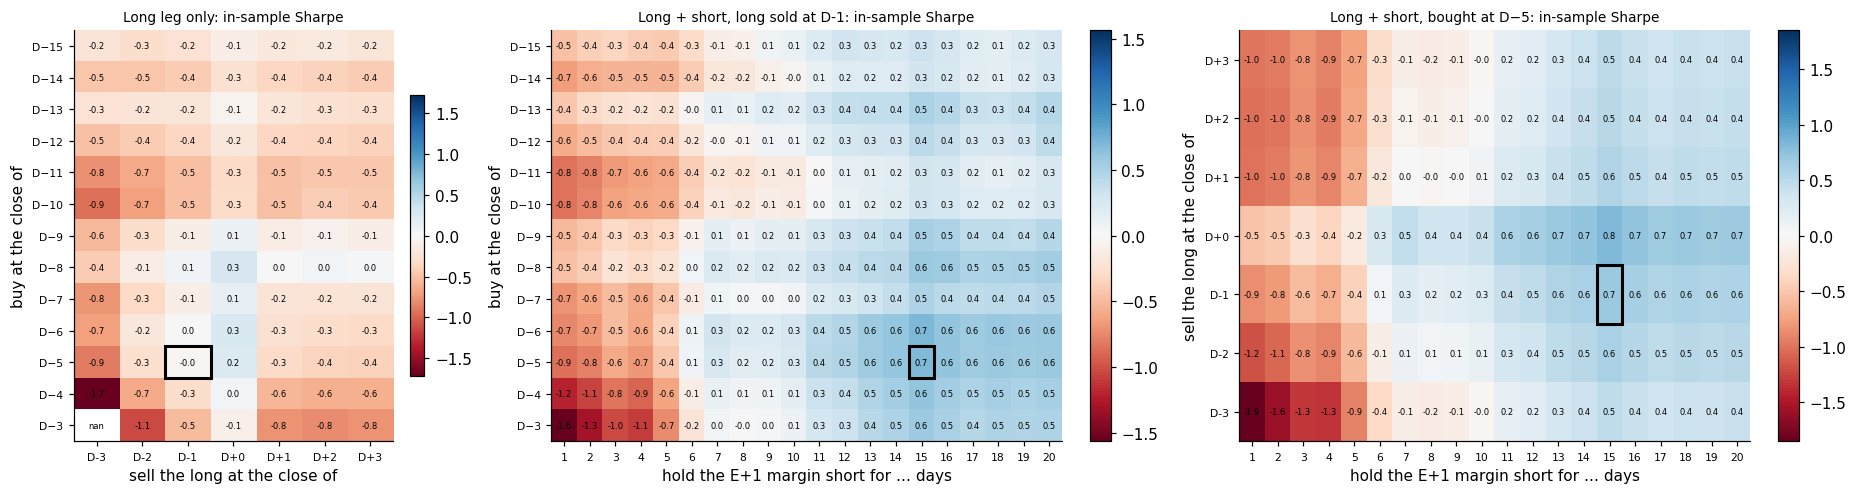

In [4]:
IS_DAY = np.arange(T) < CUT
sharpe = lambda d: d.mean() / d.std() * np.sqrt(252) if d.std() > 0 else np.nan

def legs(k, x, h, sel=None):
    # daily P&L series (long, short) and per-trade P&L for events known at the close of D-k
    use = (EV.lead.values >= k) if sel is None else sel
    i = np.flatnonzero(use)
    sl = (OFF_L >= -k + 1) & (OFF_L <= x)
    pl = RL[np.ix_(i, np.flatnonzero(sl))].copy()
    pl[:, -1] -= COST_L[i]
    long_d = np.zeros(T); np.add.at(long_d, DAYS_L[np.ix_(i, np.flatnonzero(sl))].ravel(), pl.ravel())
    ss = OFF_S <= h + 1
    i_s = i[EV.can_short.values[i]]
    ps = RS[np.ix_(i_s, np.flatnonzero(ss))].copy()
    ps[:, -1] -= COST_S[i_s]
    short_d = np.zeros(T); np.add.at(short_d, DAYS_S[np.ix_(i_s, np.flatnonzero(ss))].ravel(), ps.ravel())
    per_trade_l = pd.Series(pl.sum(1), index=i)
    per_trade_s = pd.Series(ps.sum(1), index=i_s).reindex(i, fill_value=0.0)
    return long_d, short_d, per_trade_l, per_trade_s

SH_L = np.full((len(K_GRID), len(X_GRID)), np.nan)        # long only
SH_S = np.full((len(K_GRID), len(H_GRID)), np.nan)        # short only (event set depends on k)
SH = np.full((len(K_GRID), len(X_GRID), len(H_GRID)), np.nan)
for a, k in enumerate(K_GRID):
    short_by_h = {}
    for c, h in enumerate(H_GRID):
        _, sd, _, _ = legs(k, 0, h)
        short_by_h[h] = sd
        SH_S[a, c] = sharpe(sd[IS_DAY])
    for b, x in enumerate(X_GRID):
        if x < -k + 1:                                     # sell before the first holding day: no trade
            continue
        ld, _, _, _ = legs(k, x, 1)
        SH_L[a, b] = sharpe(ld[IS_DAY])
        for c, h in enumerate(H_GRID):
            SH[a, b, c] = sharpe((ld + short_by_h[h])[IS_DAY])

def smooth(g):
    out = np.full_like(g, np.nan)
    for ix in np.ndindex(g.shape):
        win = tuple(slice(max(0, v - 1), v + 2) for v in ix)
        out[ix] = np.nanmean(g[win])
    return out

SM = smooth(SH)
a, b, c = np.unravel_index(np.nanargmax(SM), SM.shape)
K_, X_, H_ = int(K_GRID[a]), int(X_GRID[b]), int(H_GRID[c])
ra, rb, rc = np.unravel_index(np.nanargmax(SH), SH.shape)
print(f"chosen (smoothed grid): buy D-{K_}, sell D{X_:+d}, short E+1 -> E+1+{H_}: in-sample Sharpe {SH[a, b, c]:.2f} (smoothed {SM[a, b, c]:.2f})")
print(f"raw best cell:          buy D-{K_GRID[ra]}, sell D{X_GRID[rb]:+d}, short E+1 -> E+1+{H_GRID[rc]}: in-sample Sharpe {SH[ra, rb, rc]:.2f}")
bl = np.unravel_index(np.nanargmax(smooth(SH_L)), SH_L.shape)
print(f"long leg alone, best (smoothed): buy D-{K_GRID[bl[0]]}, sell D{X_GRID[bl[1]]:+d}, Sharpe {SH_L[bl]:.2f}")
print(f"short leg alone at k={K_}: best h = {H_GRID[np.nanargmax(SH_S[a])]} (Sharpe {np.nanmax(SH_S[a]):.2f}); "
      f"Sharpe by h: {dict(zip(H_GRID.tolist(), SH_S[a].round(2).tolist()))}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
def heat(axx, g, xt, yt, xl, yl, title, mark):
    im = axx.imshow(g, cmap="RdBu", vmin=-np.nanmax(np.abs(g)), vmax=np.nanmax(np.abs(g)), aspect="auto", origin="lower")
    axx.set_xticks(range(len(xt))); axx.set_xticklabels(xt, fontsize=7); axx.set_yticks(range(len(yt))); axx.set_yticklabels(yt, fontsize=7)
    axx.set_xlabel(xl); axx.set_ylabel(yl); axx.set_title(title, fontsize=9); axx.grid(False)
    for (r, cc), v in np.ndenumerate(g):
        axx.text(cc, r, f"{v:.1f}", ha="center", va="center", fontsize=5.5)
    axx.add_patch(plt.Rectangle((mark[1] - .5, mark[0] - .5), 1, 1, fill=False, ec="k", lw=2))
    plt.colorbar(im, ax=axx, fraction=.04)
heat(ax[0], SH_L, [f"D{x:+d}" for x in X_GRID], [f"D−{k}" for k in K_GRID], "sell the long at the close of", "buy at the close of",
     "Long leg only: in-sample Sharpe", (a, b))
heat(ax[1], SH[:, b, :], H_GRID, [f"D−{k}" for k in K_GRID], "hold the E+1 margin short for … days", "buy at the close of",
     f"Long + short, long sold at D{X_:+d}: in-sample Sharpe", (a, c))
heat(ax[2], SH[a, :, :], H_GRID, [f"D{x:+d}" for x in X_GRID], "hold the E+1 margin short for … days", "sell the long at the close of",
     f"Long + short, bought at D−{K_}: in-sample Sharpe", (b, c))
plt.tight_layout(); plt.show()

## 5. Headline: chosen parameters, in-sample and out-of-sample
**What this does.** Runs the chosen trade on the full period and splits it into its two legs. For reference it also
shows the `backtest_noahead.ipynb` trade (buy D−6, short at the close of D for 5 days) at the same spot costs. That
line is **not placeable**: its short opens inside the margin-short ban.

chosen: buy at the close of D−5, sell at the close of D-1; margin short at the close of E+1, cover at E+1+15
                        long + E+1 short (chosen)               long leg only               E+1 short leg only               reference: short at D (not placeable)              
                                        in-sample out-of-sample     in-sample out-of-sample          in-sample out-of-sample                             in-sample out-of-sample
Sharpe                                      0.692         0.513        -0.030        -0.095              0.687         0.467                                 0.669         0.990
total P&L (trade units)                     9.019         3.217        -0.143        -0.229              9.162         3.446                                 3.979         2.695
max drawdown                               -5.703        -2.690        -1.968        -2.009             -5.934        -3.405                                -1.904        -0.927
trades

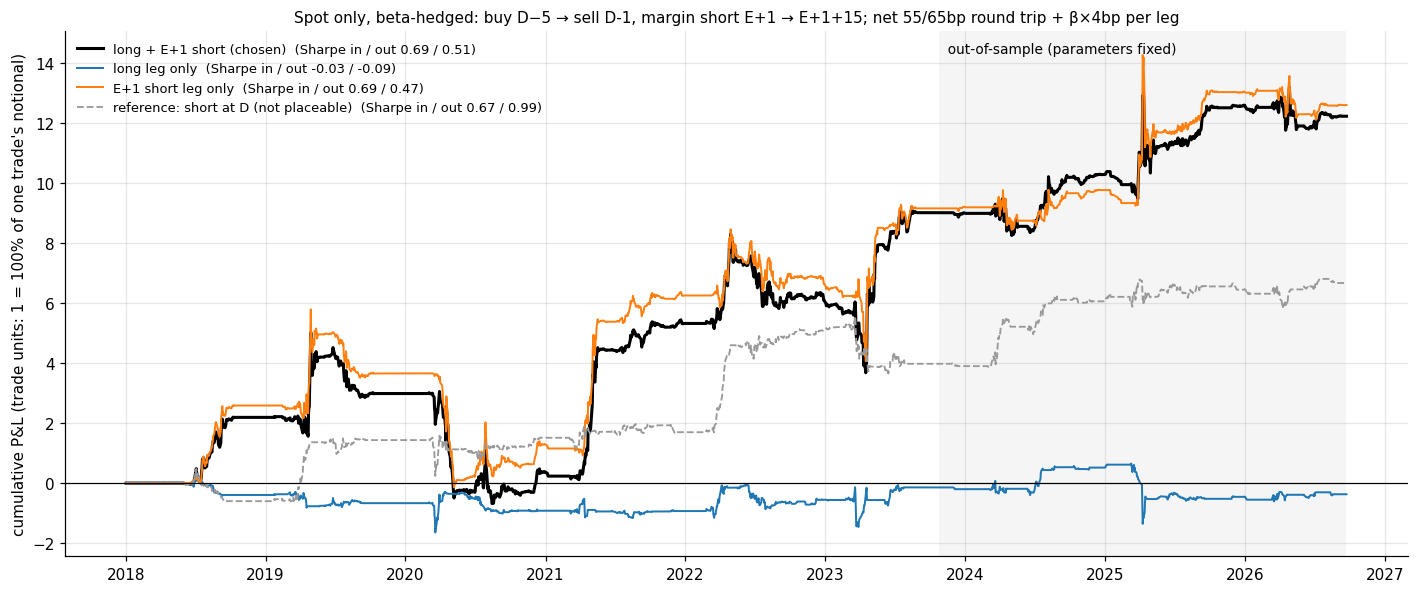


chosen trade by year:
      trades  mean net bp  long bp  short bp   hit  Sharpe                   period
year                                                                               
2018      39       562.11  -101.41    663.51  0.62    2.23                in-sample
2019     163        48.77   -16.78     65.55  0.57    0.30                in-sample
2020     111      -248.12   -22.72   -225.40  0.48   -1.11                in-sample
2021      83       613.44    -1.36    614.81  0.70    2.56                in-sample
2022     183        32.80    20.61     12.19  0.51    0.34                in-sample
2023     178       172.49    19.81    152.68  0.56    1.12  in-sample/out-of-sample
2024      79       163.88    91.16     72.73  0.57    0.76            out-of-sample
2025     116       195.90   -84.10    280.01  0.57    0.79            out-of-sample
2026      27      -121.02    32.08   -153.09  0.52   -0.29            out-of-sample


In [5]:
ld, sd, pl, ps = legs(K_, X_, H_)
use = EV.lead.values >= K_
# reference: buy D-6, sell D, short at the close of D (inside the ban) until D+5, same spot costs
i6 = np.flatnonzero(EV.lead.values >= 6)
OFF_R = np.arange(-5, 6); DAYS_R = EV.D.values[i6, None] + OFF_R[None, :]
pr = np.where(OFF_R <= 0, 1.0, -1.0)[None, :] * (np.nan_to_num(Rv[DAYS_R, EV.j.values[i6, None]]) - EV.beta.values[i6, None] * HEDGE_R[DAYS_R])
pr[:, OFF_R == 0] -= COST_L[i6, None]; pr[:, -1] -= COST_S[i6]
ref = np.zeros(T); np.add.at(ref, DAYS_R.ravel(), pr.ravel())

SERIES = {f"long + E+1 short (chosen)": ld + sd, "long leg only": ld, "E+1 short leg only": sd,
          "reference: short at D (not placeable)": ref}
per_trade = {f"long + E+1 short (chosen)": pl + ps, "long leg only": pl, "E+1 short leg only": ps[EV.can_short.values[ps.index]],
             "reference: short at D (not placeable)": pd.Series(pr.sum(1), index=i6)}

rows = {}
for nm, s in SERIES.items():
    pt = per_trade[nm]; per = EV.period.values[pt.index]
    for p, dm in [("in-sample", IS_DAY), ("out-of-sample", ~IS_DAY)]:
        x = pt.values[per == p]; d = s[dm]; dd = np.cumsum(d)
        rows[(nm, p)] = {"Sharpe": sharpe(d), "total P&L (trade units)": d.sum(), "max drawdown": (dd - np.maximum.accumulate(dd)).min(),
                         "trades": len(x), "mean net / trade bp": x.mean() * 1e4, "hit rate": (x > 0).mean(),
                         "t (per trade)": x.mean() / x.std() * np.sqrt(len(x)), "corr with TAIEX": np.corrcoef(d, taiex[dm])[0, 1]}
print(f"chosen: buy at the close of D−{K_}, sell at the close of D{X_:+d}; margin short at the close of E+1, cover at E+1+{H_}")
print(pd.DataFrame(rows).round(3).to_string())

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.axvspan(cal[CUT], cal[-1], color="0.5", alpha=.08, lw=0)
ax.text(cal[CUT], .98, "  out-of-sample (parameters fixed)", transform=ax.get_xaxis_transform(), va="top", fontsize=9)
sty = {f"long + E+1 short (chosen)": dict(color="k", lw=2), "long leg only": dict(color="C0", lw=1.3),
       "E+1 short leg only": dict(color="C1", lw=1.3), "reference: short at D (not placeable)": dict(color="0.6", lw=1.2, ls="--")}
for nm, s in SERIES.items():
    ax.plot(cal, np.cumsum(s), label=f"{nm}  (Sharpe in / out {rows[(nm, 'in-sample')]['Sharpe']:.2f} / {rows[(nm, 'out-of-sample')]['Sharpe']:.2f})", **sty[nm])
ax.axhline(0, color="k", lw=.8)
ax.set_ylabel("cumulative P&L (trade units: 1 = 100% of one trade's notional)")
ax.set_title(f"Spot only, beta-hedged: buy D−{K_} → sell D{X_:+d}, margin short E+1 → E+1+{H_}; net {COST_LONG_BPS}/{COST_SHORT_BPS}bp "
             f"round trip + β×{2 * HEDGE_BPS}bp per leg", fontsize=10)
ax.legend(fontsize=8.5, loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

yr = []
pt = per_trade["long + E+1 short (chosen)"]; Dd = EV.Ddate.values[pt.index]
for y in sorted(set(pd.DatetimeIndex(Dd).year)):
    tm = pd.DatetimeIndex(Dd).year == y; dm = cal.year == y
    yr.append({"year": y, "trades": tm.sum(), "mean net bp": pt.values[tm].mean() * 1e4, "long bp": pl.values[tm].mean() * 1e4,
               "short bp": ps.values[tm].mean() * 1e4, "hit": (pt.values[tm] > 0).mean(), "Sharpe": sharpe((ld + sd)[dm]),
               "period": "/".join(sorted(set(EV.period.values[pt.index][tm])))})
print("\nchosen trade by year:")
print(pd.DataFrame(yr).set_index("year").round(2).to_string())

**Interpretation.**
- **Chosen on the smoothed in-sample grid:** buy at the close of D−5, sell at the close of D−1, margin short at the
  close of E+1 and cover 15 trading days later. In-sample Sharpe 0.69, out-of-sample 0.51 (+119bp / +144bp per trade,
  t = 2.8 / 1.8). That is well below the 1.70 / 1.44 of `backtest_noahead.ipynb`, whose short could not be placed in spot.
- **The long leg no longer pays at spot costs.** Gross it earns roughly what it did before (~50–60bp per trade), but
  the 55bp cash round trip (30bp of it sell tax) takes all of it: long-only Sharpe is about 0 for every entry and exit
  in the grid (best smoothed cell 0.15). It earned its keep in `backtest_noahead.ipynb` only at the 20bp
  single-stock-futures cost.
- **Almost all the P&L is the E+1 short, and it needs a long hold.** Held 1–5 days it loses (Sharpe −1.8 to −0.5,
  consistent with `insample.ipynb`: the post-deadline drop is mostly over by E+1 ≈ D+4). Held 11–20 days it turns
  positive (Sharpe 0.4–0.7), a slow drift down in high-short-interest names after the ban rather than the forced-cover
  effect itself. It is lumpy: most of it comes in the March–May AGM season, with large losing years (2020: −248bp per
  trade) and a max drawdown of about 6 trade units in-sample.
- **The grey reference line** (same events and spot costs, short at the close of D) shows what the ban costs: its
  out-of-sample Sharpe is 0.99, but it is not placeable without single-stock futures or SBL.
- **Takeaway:** in spot only, the deadline trade is weak and mostly a 3-week post-ban short. The edge lives in the
  D → D+4 window, which needs single-stock futures (about 40% of Q5 names) or an SBL short sale.